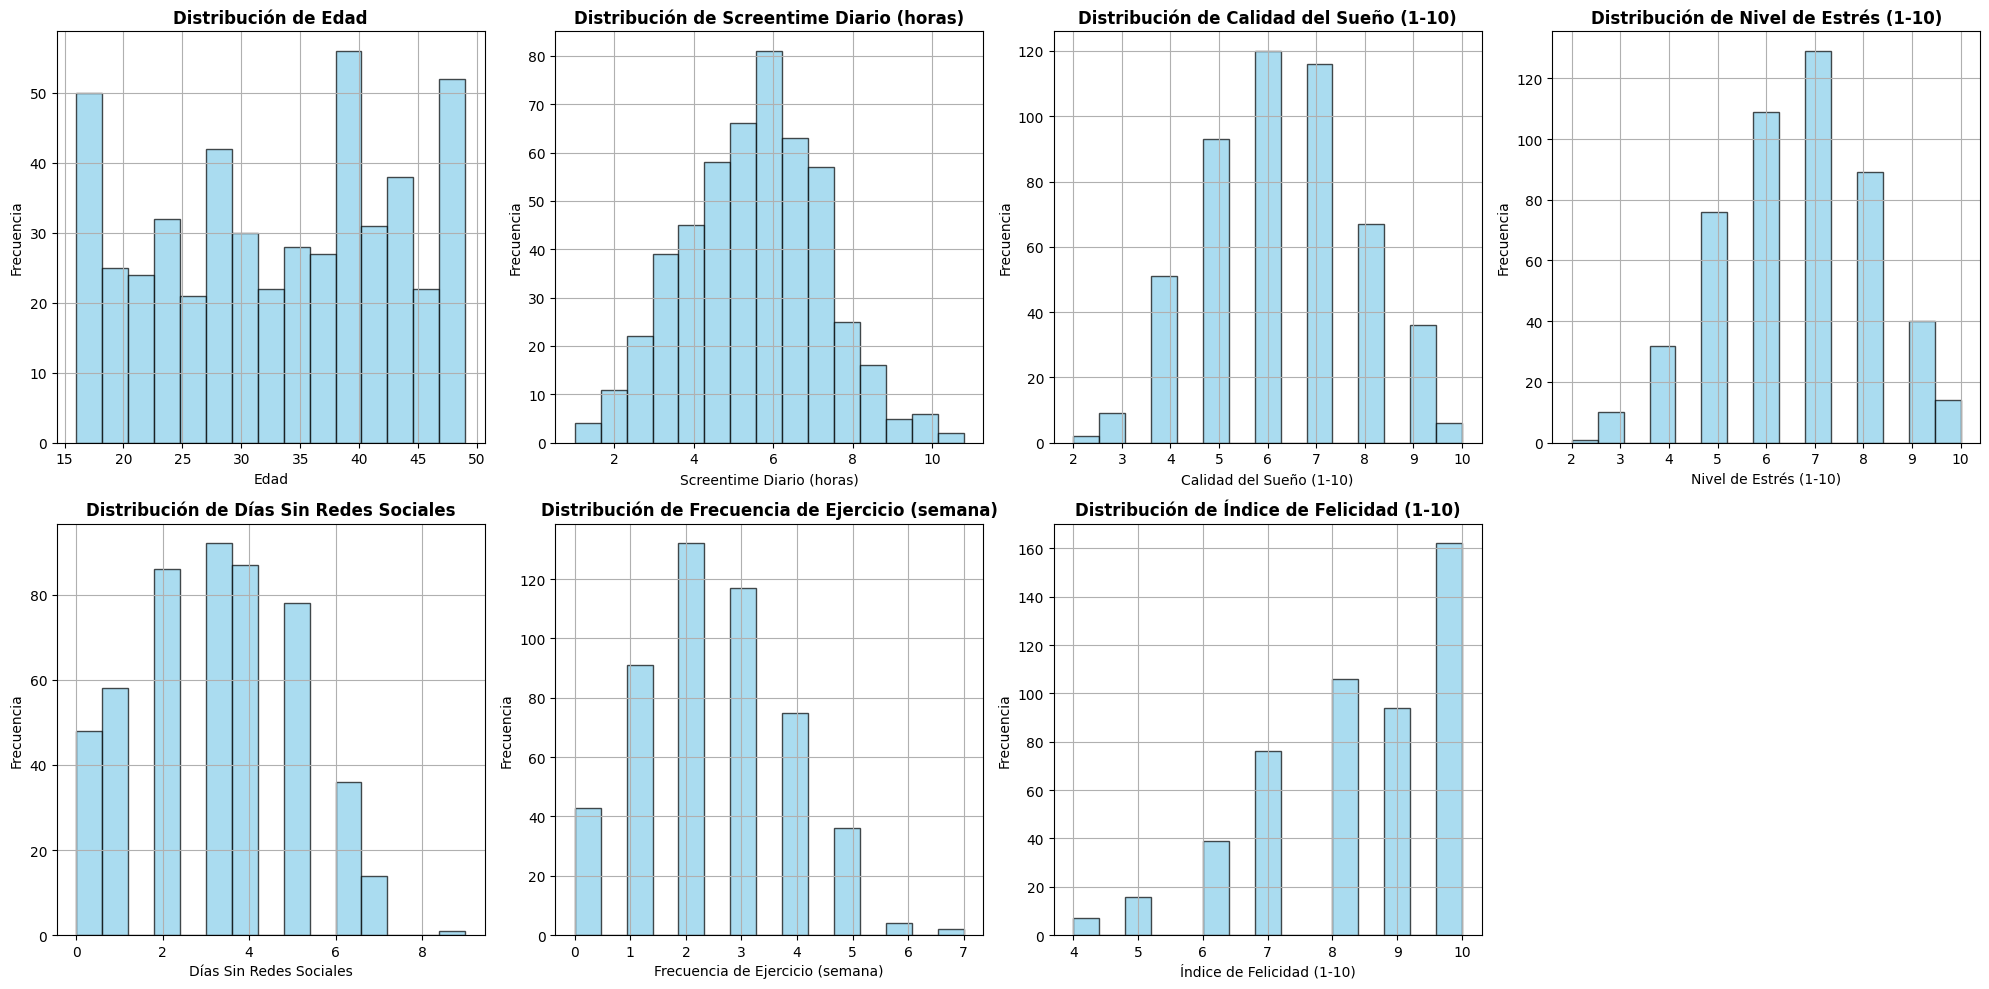

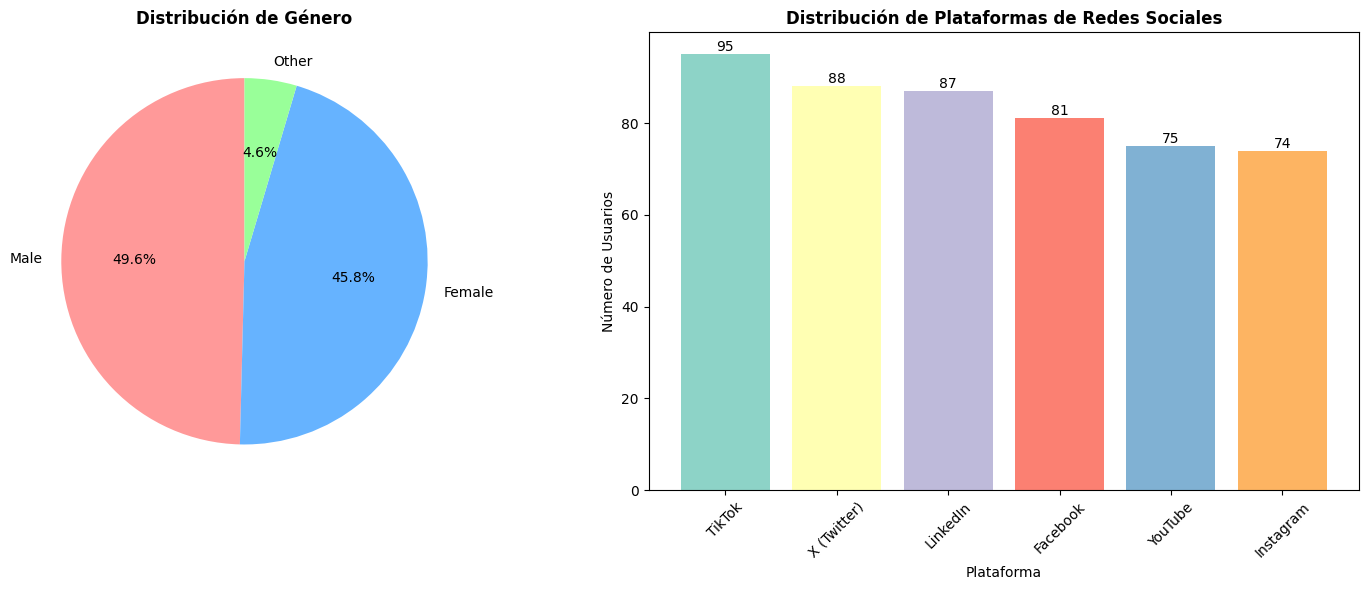

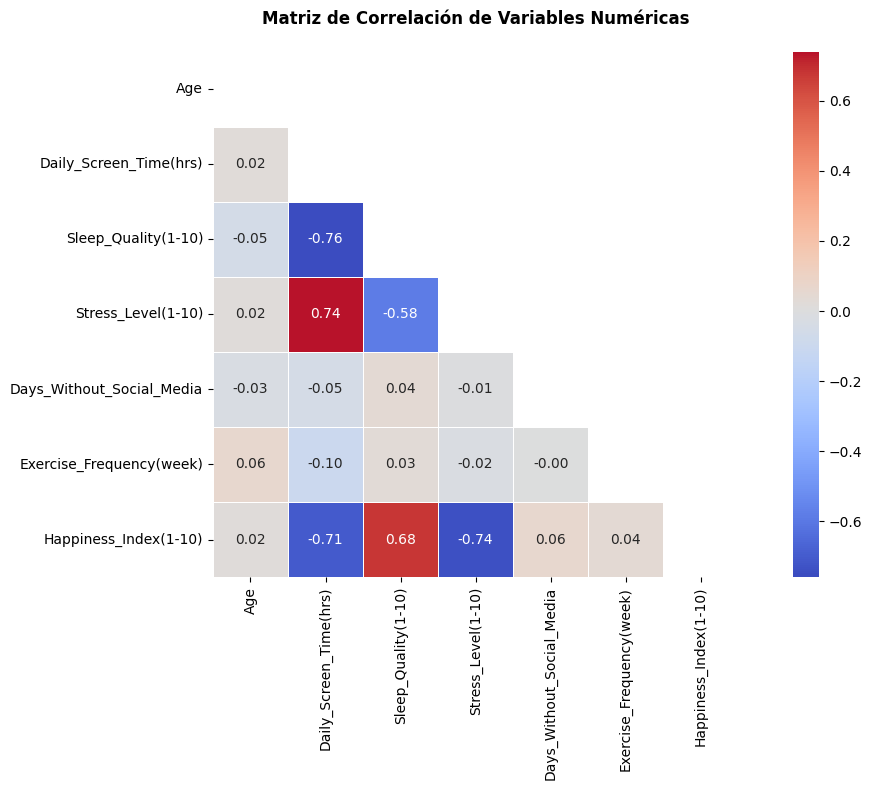

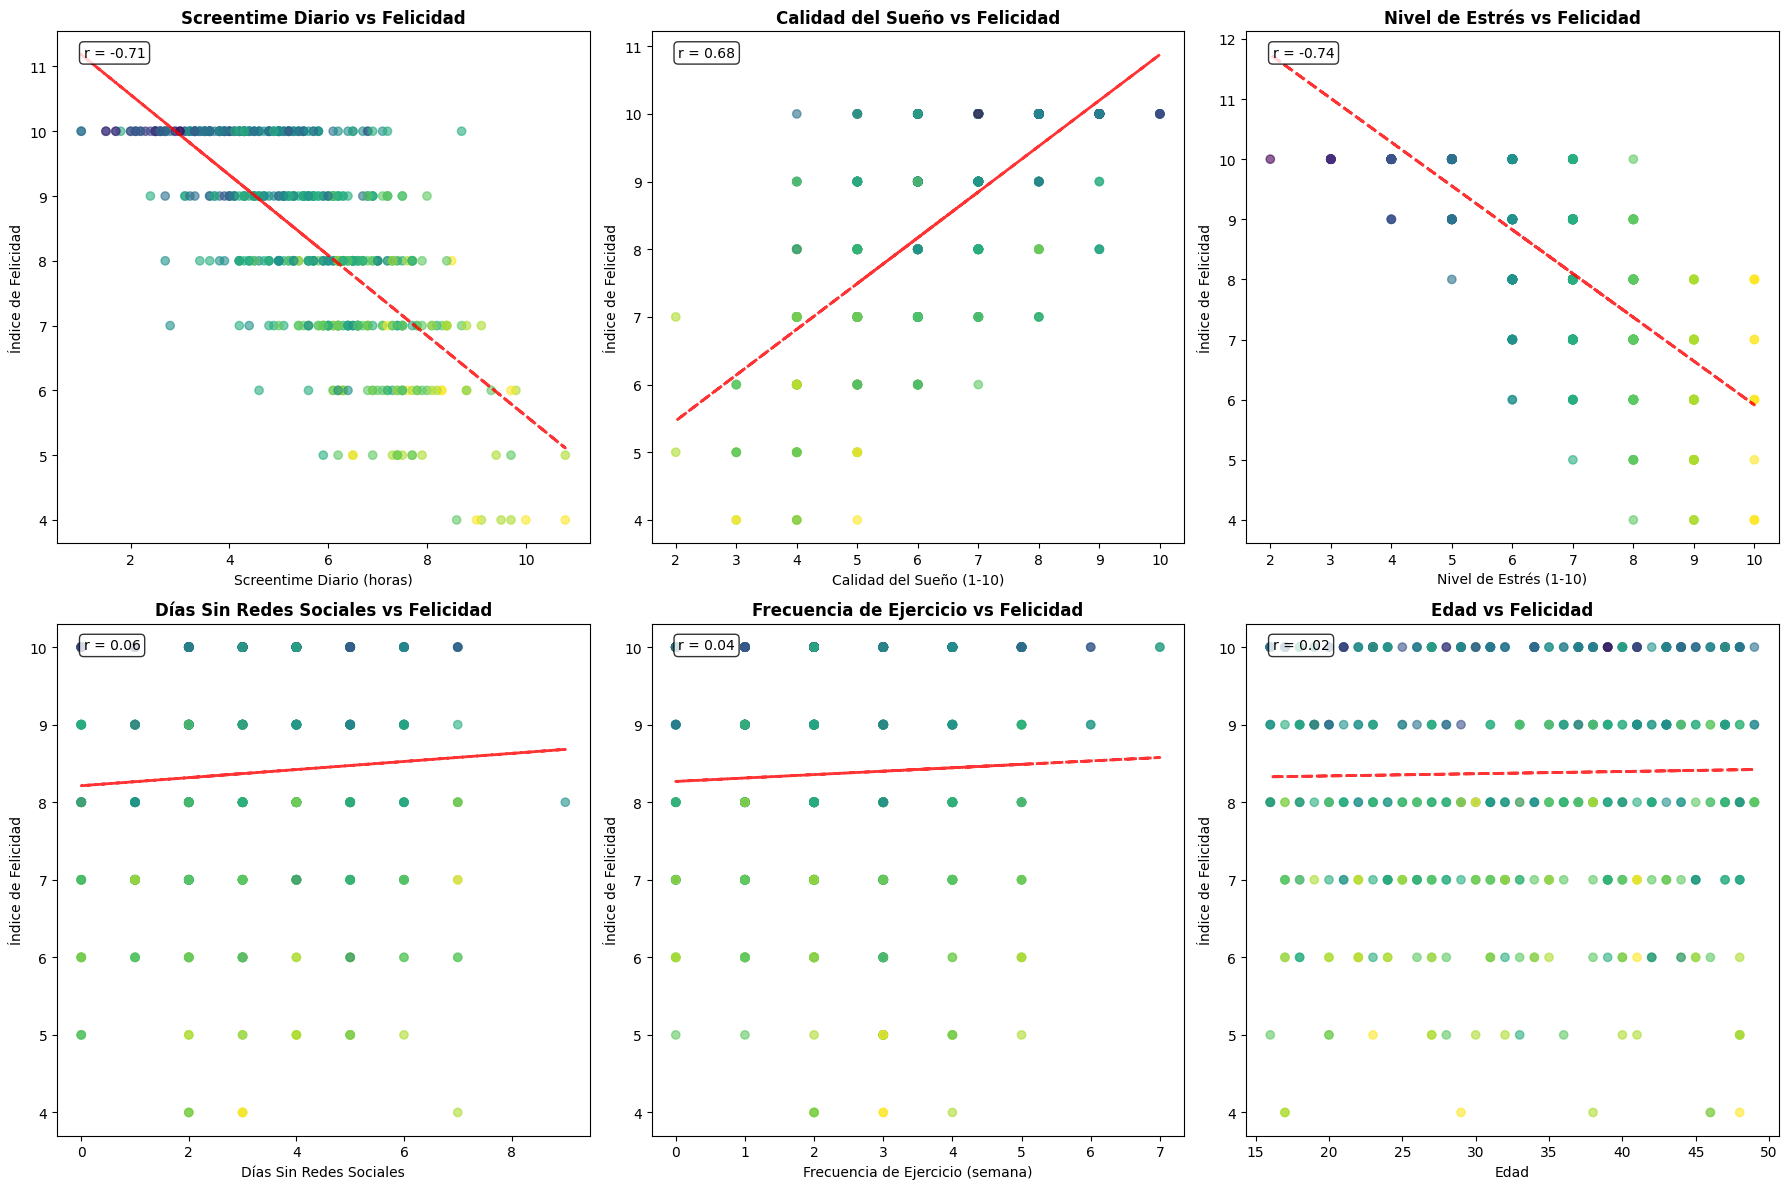

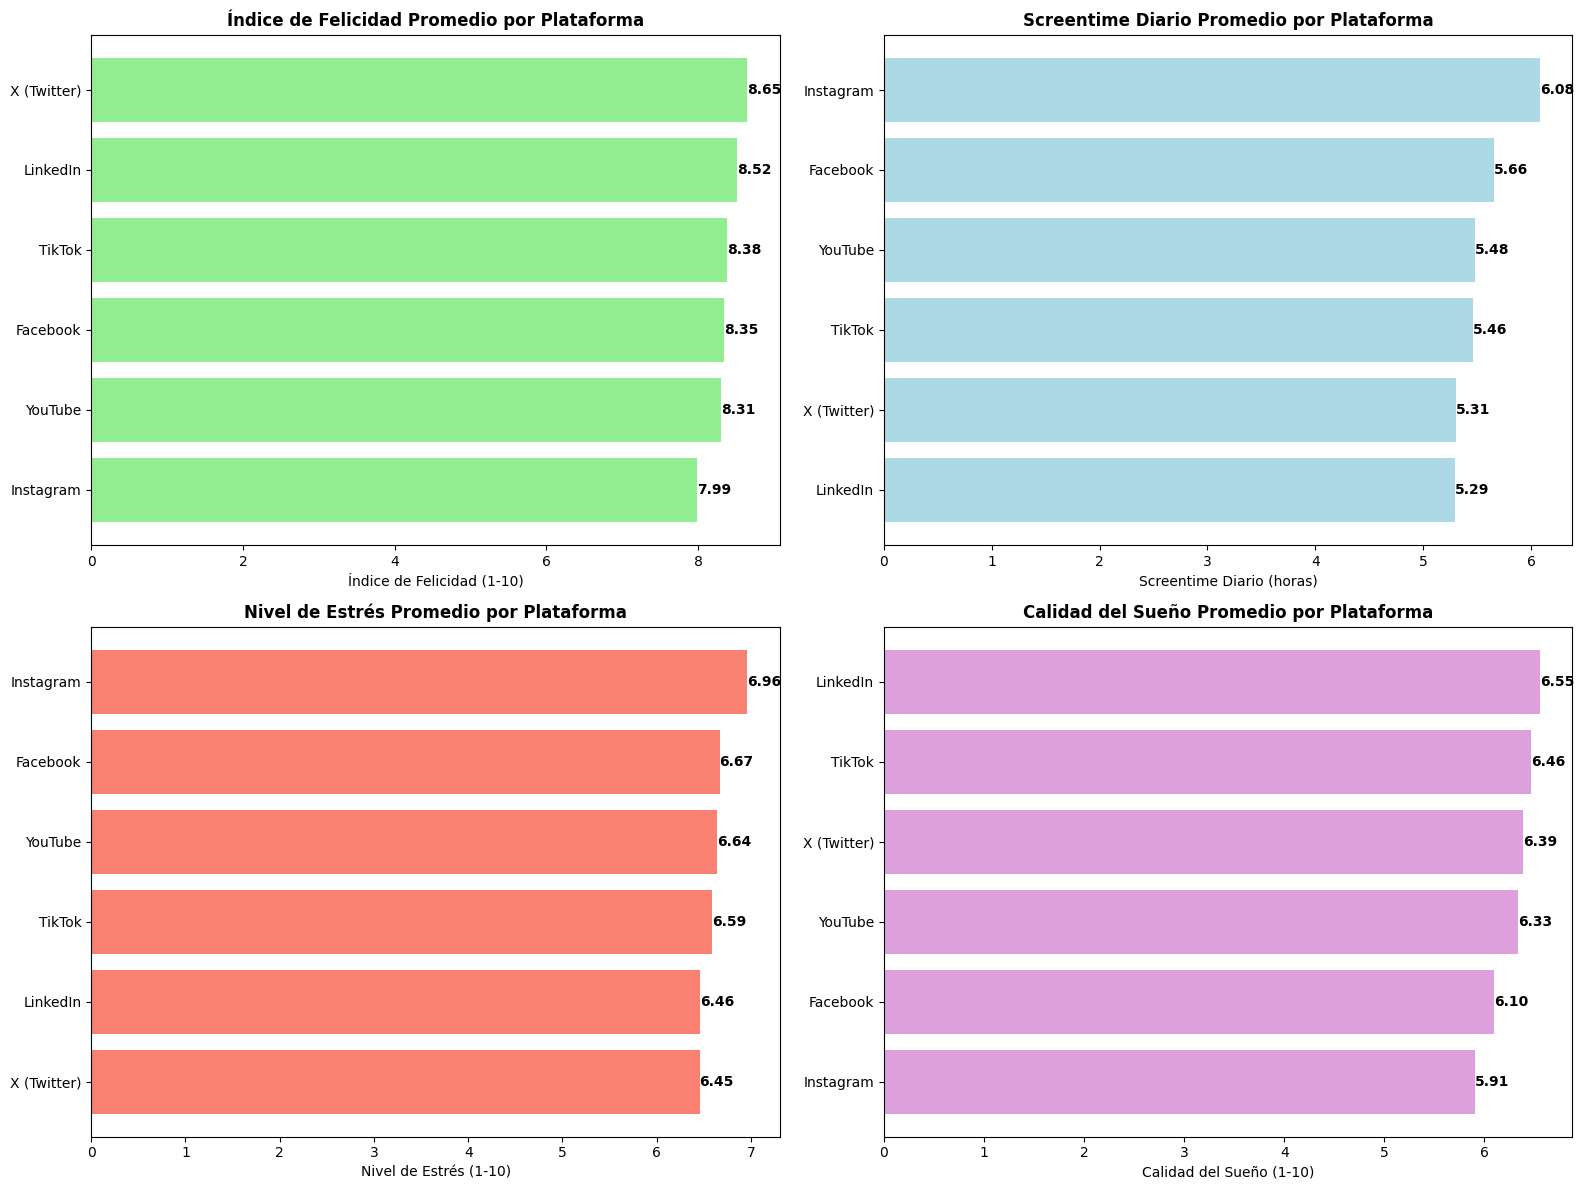

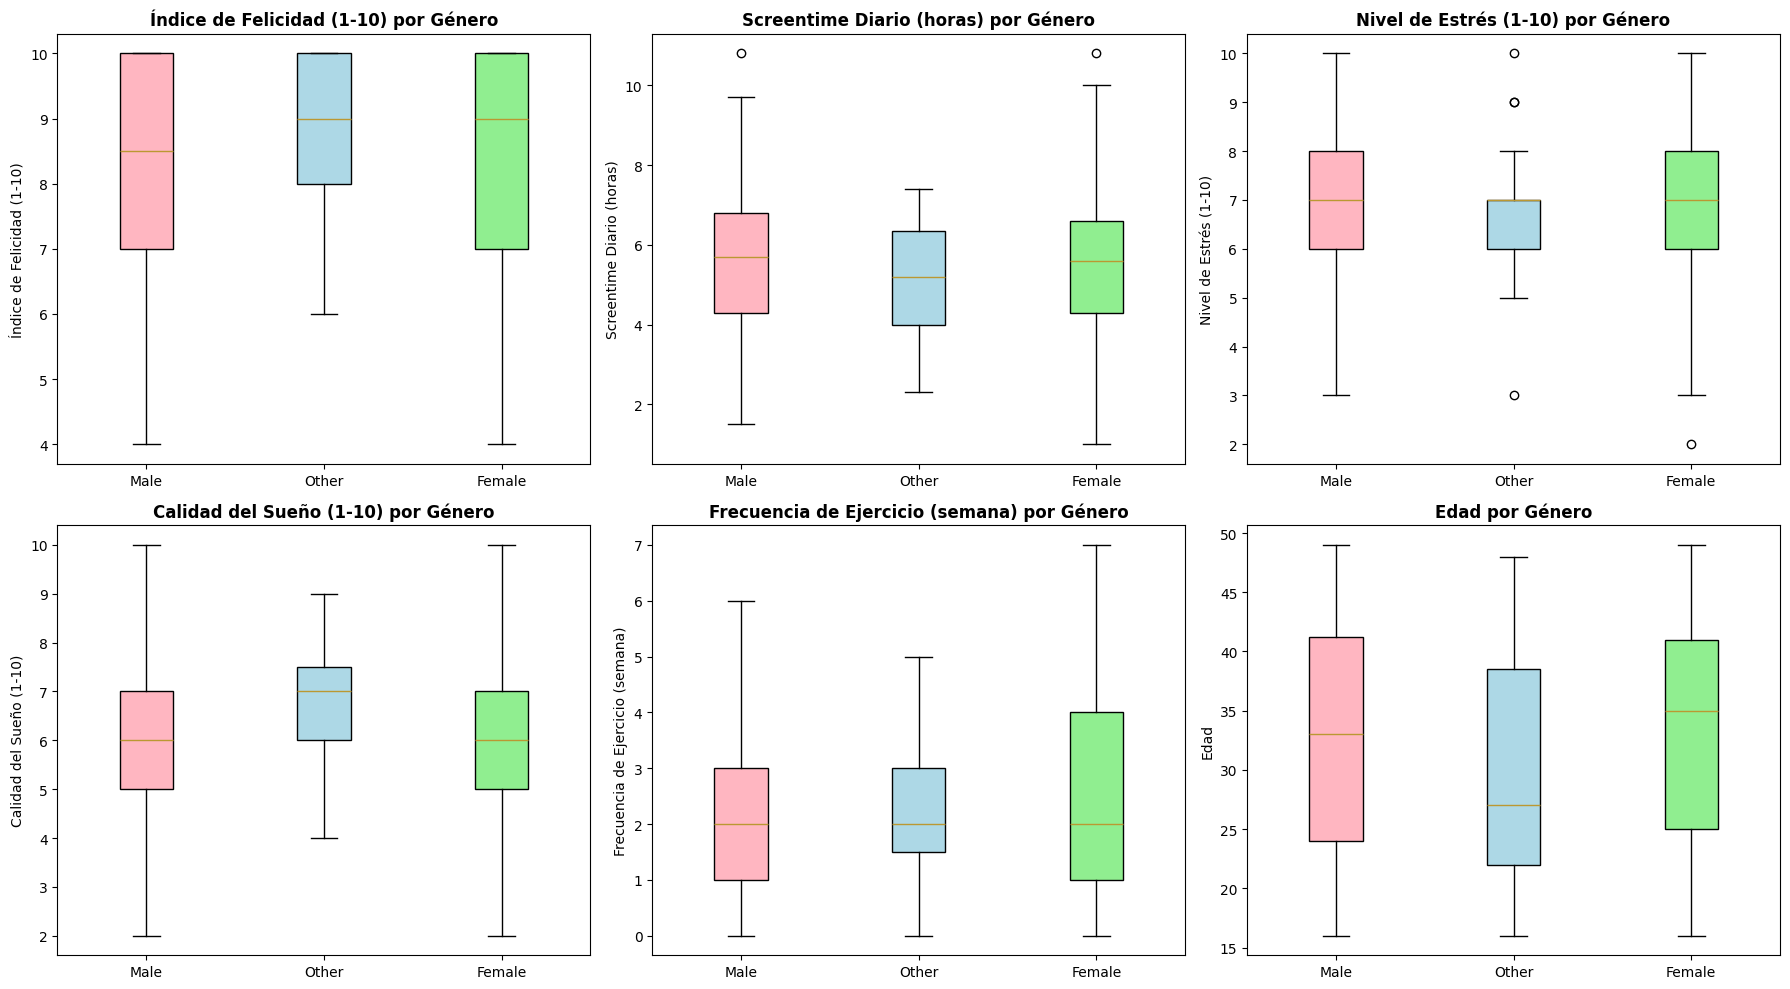

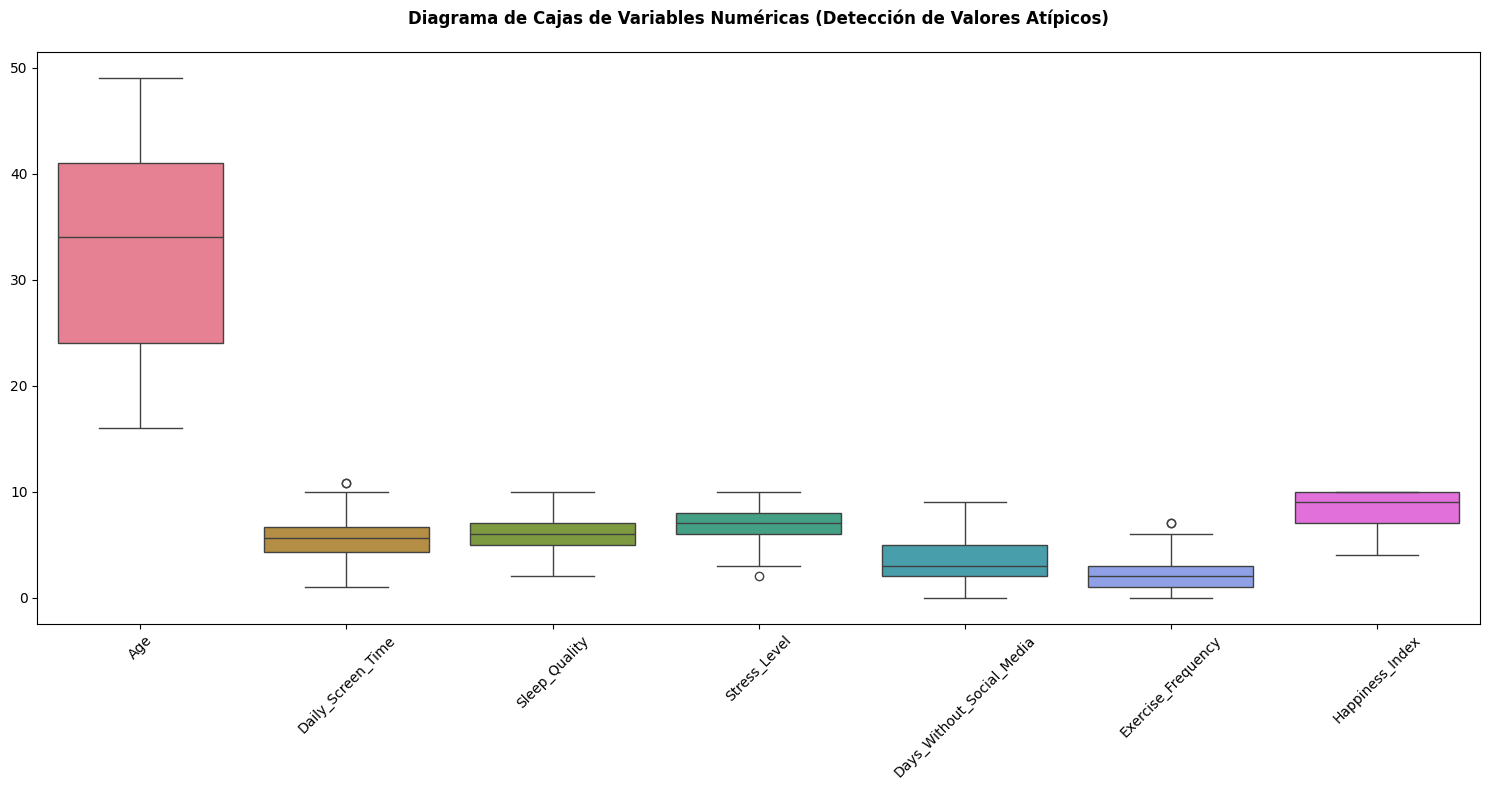

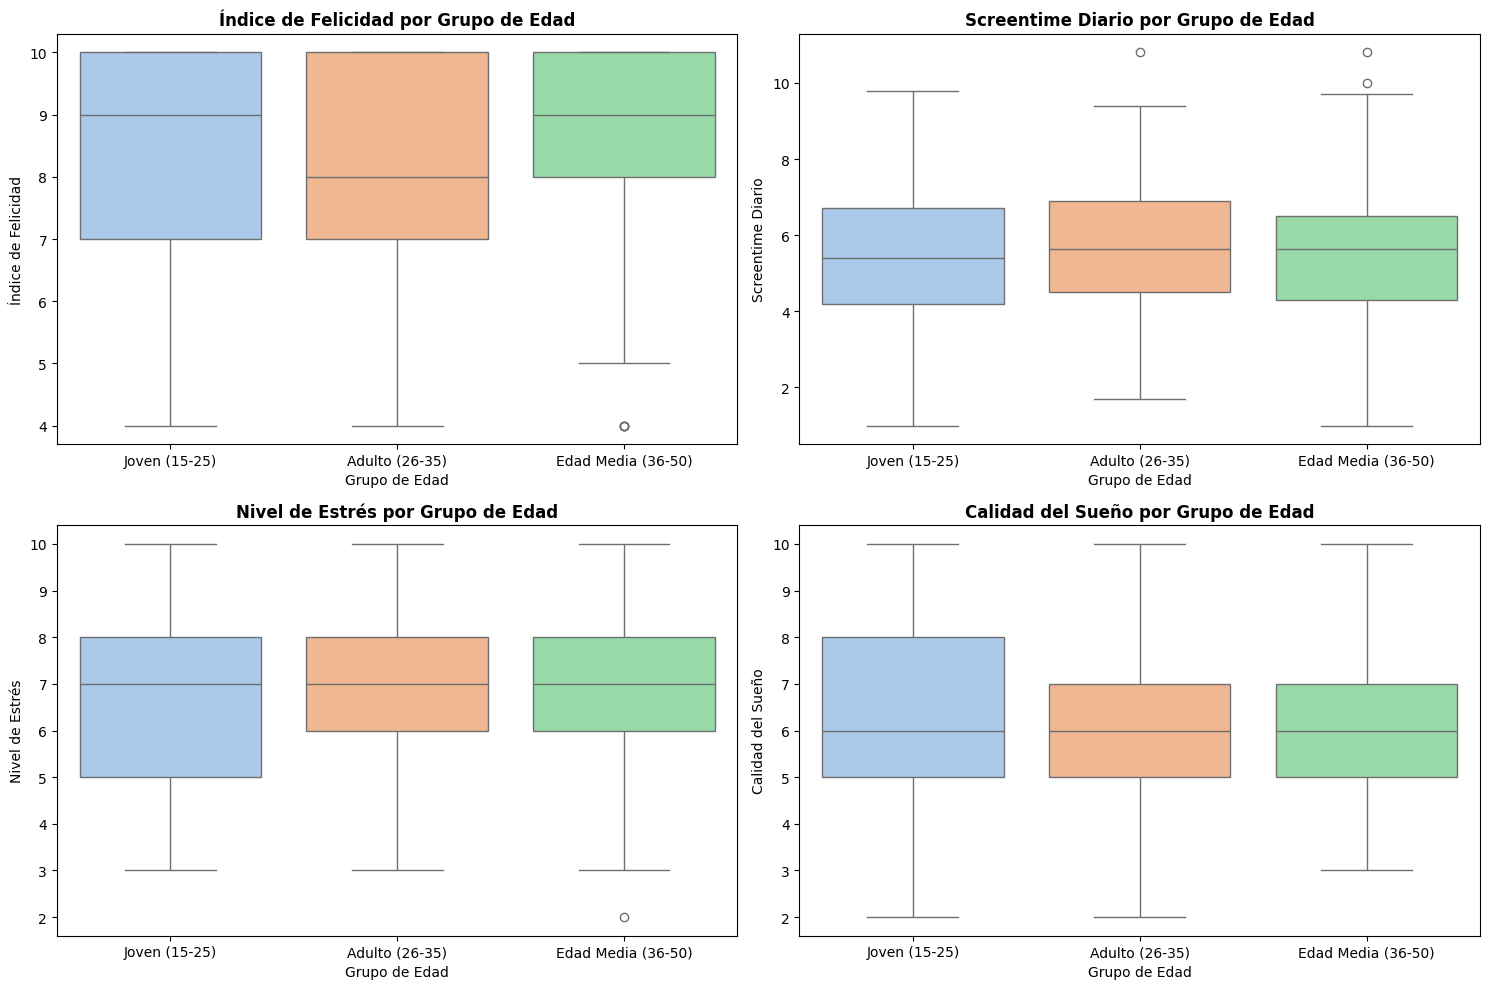

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path

DATA_PATH = Path("data/Mental_Health_and_Social_Media_Balance_Dataset.csv")

# Set style for better visualizations
plt.style.use('default')
sns.set_palette("husl")

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("="*50)
print("ANÁLISIS EXPLORATORIO DE DATOS - REDES SOCIALES Y SALUD MENTAL")
print("="*50)

# 1. BASIC DATA OVERVIEW
print("\n1. INFORMACIÓN BÁSICA DE LOS DATOS")
print("="*30)
print(f"Forma del Conjunto de Datos: {df.shape}")
print(f"\nPrimeras 5 filas:")


print(f"\nTipos de Datos:")
print(df.dtypes)

print(f"\nValores Faltantes:")
print(df.isnull().sum())

print(f"\nEstadísticas Básicas:")
print(df.describe())

# 2. UNIVARIATE ANALYSIS
print("\n\n2. ANÁLISIS UNIVARIANTE")
print("="*30)

# Numerical variables distribution
numerical_cols = ['Age', 'Daily_Screen_Time(hrs)', 'Sleep_Quality(1-10)',
                  'Stress_Level(1-10)', 'Days_Without_Social_Media',
                  'Exercise_Frequency(week)', 'Happiness_Index(1-10)']

# Create subplots for numerical variables (2 rows, 4 columns to fit all 7 variables)
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for i, col in enumerate(numerical_cols):
    df[col].hist(bins=15, ax=axes[i], alpha=0.7, color='skyblue', edgecolor='black')
    axes[i].set_title(f'Distribución de {col.replace("(hrs)", " (horas)").replace("(1-10)", " (1-10)").replace("(week)", " (semana)").replace("Age", "Edad").replace("Daily_Screen_Time", "Screentime Diario").replace("Sleep_Quality", "Calidad del Sueño").replace("Stress_Level", "Nivel de Estrés").replace("Days_Without_Social_Media", "Días Sin Redes Sociales").replace("Exercise_Frequency", "Frecuencia de Ejercicio").replace("Happiness_Index", "Índice de Felicidad")}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col.replace("(hrs)", " (horas)").replace("(1-10)", " (1-10)").replace("(week)", " (semana)").replace("Age", "Edad").replace("Daily_Screen_Time", "Screentime Diario").replace("Sleep_Quality", "Calidad del Sueño").replace("Stress_Level", "Nivel de Estrés").replace("Days_Without_Social_Media", "Días Sin Redes Sociales").replace("Exercise_Frequency", "Frecuencia de Ejercicio").replace("Happiness_Index", "Índice de Felicidad"))
    axes[i].set_ylabel('Frecuencia')

# Remove the empty subplot (8th one)
fig.delaxes(axes[7])
plt.tight_layout()
plt.show()

# Categorical variables
categorical_cols = ['Gender', 'Social_Media_Platform']

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gender distribution
gender_counts = df['Gender'].value_counts()
axes[0].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%',
            startangle=90, colors=['#ff9999','#66b3ff','#99ff99'])
axes[0].set_title('Distribución de Género', fontweight='bold')

# Social Media Platform distribution
platform_counts = df['Social_Media_Platform'].value_counts()
bars = axes[1].bar(platform_counts.index, platform_counts.values,
                   color=plt.cm.Set3(np.arange(len(platform_counts))))
axes[1].set_title('Distribución de Plataformas de Redes Sociales', fontweight='bold')
axes[1].set_xlabel('Plataforma')
axes[1].set_ylabel('Número de Usuarios')
plt.xticks(rotation=45)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# 3. BIVARIATE ANALYSIS
print("\n\n3. ANÁLISIS BIVARIANTE")
print("="*30)

# Correlation matrix
plt.figure(figsize=(12, 8))
correlation_matrix = df[numerical_cols].corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, mask=mask, fmt='.2f')
plt.title('Matriz de Correlación de Variables Numéricas', fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Happiness Index vs other variables - using 2x3 grid for 6 relationships
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

relationships = [
    ('Daily_Screen_Time(hrs)', 'Screentime Diario vs Felicidad'),
    ('Sleep_Quality(1-10)', 'Calidad del Sueño vs Felicidad'),
    ('Stress_Level(1-10)', 'Nivel de Estrés vs Felicidad'),
    ('Days_Without_Social_Media', 'Días Sin Redes Sociales vs Felicidad'),
    ('Exercise_Frequency(week)', 'Frecuencia de Ejercicio vs Felicidad'),
    ('Age', 'Edad vs Felicidad')
]

for i, (col, title) in enumerate(relationships):
    # Scatter plot
    scatter = axes[i].scatter(df[col], df['Happiness_Index(1-10)'],
                             alpha=0.6, c=df['Stress_Level(1-10)'], cmap='viridis')
    axes[i].set_xlabel(col.replace("(hrs)", " (horas)").replace("(1-10)", " (1-10)").replace("(week)", " (semana)").replace("Age", "Edad").replace("Daily_Screen_Time", "Screentime Diario").replace("Sleep_Quality", "Calidad del Sueño").replace("Stress_Level", "Nivel de Estrés").replace("Days_Without_Social_Media", "Días Sin Redes Sociales").replace("Exercise_Frequency", "Frecuencia de Ejercicio"))
    axes[i].set_ylabel('Índice de Felicidad')
    axes[i].set_title(title, fontweight='bold')

    # Add trend line
    z = np.polyfit(df[col], df['Happiness_Index(1-10)'], 1)
    p = np.poly1d(z)
    axes[i].plot(df[col], p(df[col]), "r--", alpha=0.8, linewidth=2)

    # Add correlation coefficient
    corr = df[col].corr(df['Happiness_Index(1-10)'])
    axes[i].text(0.05, 0.95, f'r = {corr:.2f}', transform=axes[i].transAxes,
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

# 4. PLATFORM-WISE ANALYSIS
print("\n\n4. ANÁLISIS POR PLATAFORMA")
print("="*30)

# Average metrics by platform
platform_analysis = df.groupby('Social_Media_Platform').agg({
    'Happiness_Index(1-10)': 'mean',
    'Daily_Screen_Time(hrs)': 'mean',
    'Stress_Level(1-10)': 'mean',
    'Sleep_Quality(1-10)': 'mean',
    'Exercise_Frequency(week)': 'mean',
    'User_ID': 'count'
}).round(2)

platform_analysis = platform_analysis.rename(columns={'User_ID': 'User_Count'})
print("Métricas Promedio por Plataforma:")
print(platform_analysis)

# Visualization of platform comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

metrics_to_plot = [
    ('Happiness_Index(1-10)', 'lightgreen', 'Índice de Felicidad Promedio por Plataforma'),
    ('Daily_Screen_Time(hrs)', 'lightblue', 'Screentime Diario Promedio por Plataforma'),
    ('Stress_Level(1-10)', 'salmon', 'Nivel de Estrés Promedio por Plataforma'),
    ('Sleep_Quality(1-10)', 'plum', 'Calidad del Sueño Promedio por Plataforma')
]

for i, (metric, color, title) in enumerate(metrics_to_plot):
    row, col = i // 2, i % 2
    platform_metric = df.groupby('Social_Media_Platform')[metric].mean().sort_values()
    bars = axes[row, col].barh(platform_metric.index, platform_metric.values, color=color)
    axes[row, col].set_title(title, fontweight='bold')
    axes[row, col].set_xlabel(metric.replace("(hrs)", " (horas)").replace("(1-10)", " (1-10)").replace("(week)", " (semana)").replace("Happiness_Index", "Índice de Felicidad").replace("Daily_Screen_Time", "Screentime Diario").replace("Stress_Level", "Nivel de Estrés").replace("Sleep_Quality", "Calidad del Sueño"))

    # Add value labels
    for bar in bars:
        width = bar.get_width()
        axes[row, col].text(width, bar.get_y() + bar.get_height()/2.,
                           f'{width:.2f}', ha='left', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 5. GENDER-WISE ANALYSIS
print("\n\n5. ANÁLISIS POR GÉNERO")
print("="*30)

gender_analysis = df.groupby('Gender').agg({
    'Happiness_Index(1-10)': 'mean',
    'Daily_Screen_Time(hrs)': 'mean',
    'Stress_Level(1-10)': 'mean',
    'Sleep_Quality(1-10)': 'mean',
    'Exercise_Frequency(week)': 'mean',
    'Age': 'mean',
    'User_ID': 'count'
}).round(2)

gender_analysis = gender_analysis.rename(columns={'User_ID': 'User_Count'})
print("Métricas Promedio por Género:")
print(gender_analysis)

# Visualization of gender differences
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
gender_metrics_raw = ['Happiness_Index(1-10)', 'Daily_Screen_Time(hrs)', 'Stress_Level(1-10)',
                  'Sleep_Quality(1-10)', 'Exercise_Frequency(week)', 'Age']
gender_metrics_translated = ['Índice de Felicidad (1-10)', 'Screentime Diario (horas)', 'Nivel de Estrés (1-10)',
                               'Calidad del Sueño (1-10)', 'Frecuencia de Ejercicio (semana)', 'Edad']

for i, metric_raw in enumerate(gender_metrics_raw):
    row, col = i // 3, i % 3
    gender_data = [df[df['Gender'] == gender][metric_raw] for gender in df['Gender'].unique()]
    box = axes[row, col].boxplot(gender_data, labels=df['Gender'].unique(),
                                patch_artist=True)

    # Add colors to boxes
    colors = ['lightpink', 'lightblue', 'lightgreen']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)

    axes[row, col].set_title(f'{gender_metrics_translated[i]} por Género', fontweight='bold')
    axes[row, col].set_ylabel(gender_metrics_translated[i])

plt.tight_layout()
plt.show()

# 6. OUTLIER DETECTION
print("\n\n6. DETECCIÓN DE VALORES ATÍPICOS")
print("="*30)

plt.figure(figsize=(15, 8))
df_boxplot = df[numerical_cols].copy()
# Clean column names for display
df_boxplot.columns = [col.replace('(1-10)', '').replace('(hrs)', '').replace('(week)', '')
                      for col in numerical_cols]
sns.boxplot(data=df_boxplot)
plt.title('Diagrama de Cajas de Variables Numéricas (Detección de Valores Atípicos)', fontweight='bold', pad=20)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. KEY INSIGHTS AND STATISTICAL TESTS
print("\n\n7. ANÁLISIS ESTADÍSTICO")
print("="*30)

# Correlation with happiness index
happiness_correlations = df[numerical_cols].corr()['Happiness_Index(1-10)'].sort_values(ascending=False)
print("Correlación con el Índice de Felicidad:")
for feature, corr in happiness_correlations.items():
    if feature != 'Happiness_Index(1-10)':
        significance = "***" if abs(corr) > 0.5 else "**" if abs(corr) > 0.3 else "*" if abs(corr) > 0.1 else ""
        print(f"{feature.replace("(hrs)", " (horas)").replace("(1-10)", " (1-10)").replace("(week)", " (semana)").replace("Age", "Edad").replace("Daily_Screen_Time", "Screentime Diario").replace("Sleep_Quality", "Calidad del Sueño").replace("Stress_Level", "Nivel de Estrés").replace("Days_Without_Social_Media", "Días Sin Redes Sociales").replace("Exercise_Frequency", "Frecuencia de Ejercicio").replace("Happiness_Index", "Índice de Felicidad")}: {corr:.3f} {significance}")

# ANOVA test for platform effect on happiness
platforms = df['Social_Media_Platform'].unique()
platform_groups = [df[df['Social_Media_Platform'] == platform]['Happiness_Index(1-10)']
                   for platform in platforms]

f_stat, p_value = stats.f_oneway(*platform_groups)
print(f"\nPrueba ANOVA - Efecto de la Plataforma en la Felicidad:")
print(f"Estadístico F: {f_stat:.3f}, valor p: {p_value:.3f}")

if p_value < 0.05:
    print("✅ Diferencia significativa en la felicidad entre plataformas (p < 0.05)")
else:
    print("❌ No hay diferencia significativa en la felicidad entre plataformas")

# 8. AGE GROUP ANALYSIS
print("\n\n8. ANÁLISIS POR GRUPO DE EDAD")
print("="*30)

# Create age groups
df['Age_Group'] = pd.cut(df['Age'], bins=[15, 25, 35, 50],
                        labels=['Joven (15-25)', 'Adulto (26-35)', 'Edad Media (36-50)'])

age_group_analysis = df.groupby('Age_Group').agg({
    'Happiness_Index(1-10)': 'mean',
    'Daily_Screen_Time(hrs)': 'mean',
    'Stress_Level(1-10)': 'mean',
    'Sleep_Quality(1-10)': 'mean',
    'User_ID': 'count'
}).round(2)

age_group_analysis = age_group_analysis.rename(columns={'User_ID': 'User_Count'})
print("Análisis por Grupo de Edad:")
print(age_group_analysis)

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
metrics = ['Happiness_Index(1-10)', 'Daily_Screen_Time(hrs)', 'Stress_Level(1-10)', 'Sleep_Quality(1-10)']
titles = ['Índice de Felicidad', 'Screentime Diario', 'Nivel de Estrés', 'Calidad del Sueño']

for i, (metric, title) in enumerate(zip(metrics, titles)):
    sns.boxplot(data=df, x='Age_Group', y=metric, ax=axes[i//2, i%2],
                palette='pastel')
    axes[i//2, i%2].set_title(f'{title} por Grupo de Edad', fontweight='bold')
    axes[i//2, i%2].set_xlabel('Grupo de Edad')
    axes[i//2, i%2].set_ylabel(title)

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("¡EDA COMPLETADO EXITOSAMENTE!")
print("="*50)

# Final summary
print("\n📊 RESUMEN DE HALLAZGOS CLAVE:")
print("-" * 25)
print(f"• El conjunto de datos contiene {len(df)} usuarios en {len(df['Social_Media_Platform'].unique())} plataformas")
print(f"• Distribución de Género: {dict(gender_counts)}")
print(f"• Puntuación promedio de felicidad: {df['Happiness_Index(1-10)'].mean():.2f}")
print(f"• Screentime promedio diario: {df['Daily_Screen_Time(hrs)'].mean():.2f} horas")
print(f"• Correlación positiva más fuerte con la felicidad: {happiness_correlations.index[1].replace("(hrs)", " (horas)").replace("(1-10)", " (1-10)").replace("(week)", " (semana)").replace("Sleep_Quality", "Calidad del Sueño") } ({happiness_correlations.iloc[1]:.3f})")
print(f"• Correlación negativa más fuerte con la felicidad: {happiness_correlations.index[-1].replace("(hrs)", " (horas)").replace("(1-10)", " (1-10)").replace("(week)", " (semana)").replace("Stress_Level", "Nivel de Estrés") } ({happiness_correlations.iloc[-1]:.3f})")

# Platform with highest happiness
happiest_platform = platform_analysis['Happiness_Index(1-10)'].idxmax()
print(f"• Plataforma con mayor felicidad: {happiest_platform} ({platform_analysis.loc[happiest_platform, 'Happiness_Index(1-10)']:.2f})")

# Platform with highest screen time
most_screen_time = platform_analysis['Daily_Screen_Time(hrs)'].idxmax()
print(f"• Plataforma con mayor Screentime: {most_screen_time} ({platform_analysis.loc[most_screen_time, 'Daily_Screen_Time(hrs)']:.2f} horas)")

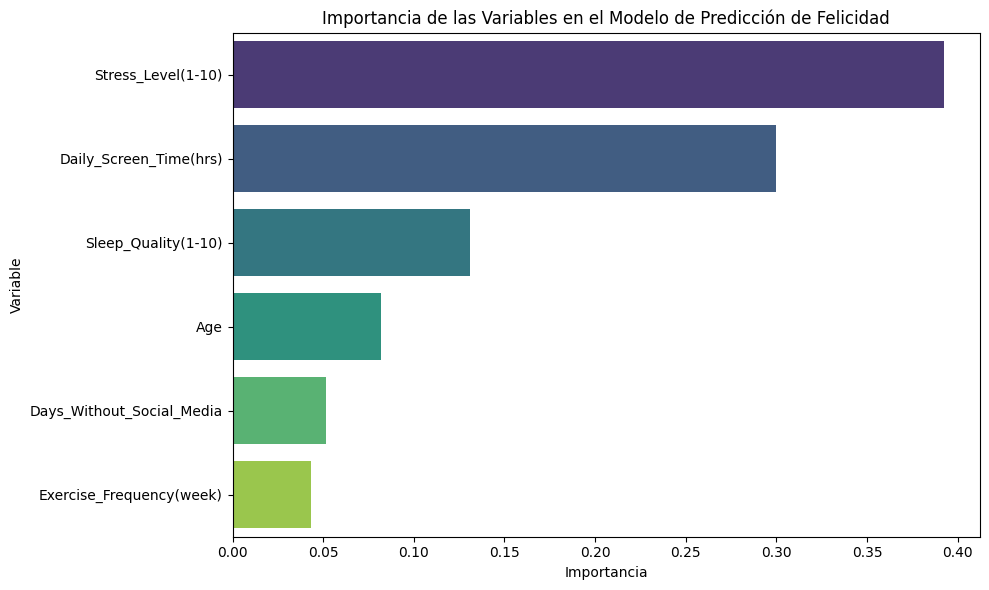

In [ ]:
# ===========================================================
# 9. MACHINE LEARNING MODEL – Random Forest (Regresión)
# ===========================================================

print("\n\n9. MODELO DE APRENDIZAJE AUTOMÁTICO")
print("="*30)
print("Entrenando modelo para predecir el Índice de Felicidad...\n")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ------------------------------
# 1. Selección de variables
# ------------------------------

numerical_cols = [
    'Age', 'Daily_Screen_Time(hrs)', 'Sleep_Quality(1-10)',
    'Stress_Level(1-10)', 'Days_Without_Social_Media',
    'Exercise_Frequency(week)'
]

target = 'Happiness_Index(1-10)'

X = df[numerical_cols]
y = df[target]

# ------------------------------
# 2. División train/test
# ------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ------------------------------
# 3. Escalado
# ------------------------------

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------
# 4. Random Forest Regressor
# ------------------------------

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(X_train_scaled, y_train)
predictions = model.predict(X_test_scaled)

# ------------------------------
# 5. Evaluación del modelo
# ------------------------------

mse = mean_squared_error(y_test, predictions)
rmse = mse ** 0.5
r2 = r2_score(y_test, predictions)

print("Resultados del Modelo:")
print(f"- RMSE: {rmse:.3f}")
print(f"- R²: {r2:.3f}")

# ------------------------------
# 6. Importancia de las variables
# ------------------------------

importances = model.feature_importances_
importance_df = pd.DataFrame({
    'Variable': numerical_cols,
    'Importancia': importances
}).sort_values('Importancia', ascending=False)

print("\nImportancia de las Variables:")
print(importance_df)

# Visualización
plt.figure(figsize=(10,6))
sns.barplot(data=importance_df, x='Importancia', y='Variable', palette='viridis')
plt.title('Importancia de las Variables en el Modelo de Predicción de Felicidad')
plt.tight_layout()
plt.show()
